# 03 - AutoML versus manual tuning (Step 3)

Three AutoML tools get the same `train` split (160k rows, all 2,568 features) and the same time
budget each, and are scored once on `test_random` and `test_future`, exactly like the tuned LightGBM
from notebook 02:

* **FLAML** (Microsoft): a cost-aware search over several learners (LightGBM, XGBoost, random
  forests, ...). It starts with cheap configurations and moves to expensive ones.
* **AutoGluon** (Amazon): trains a fixed portfolio of models with preset settings and combines them
  with a weighted ensemble (and optionally stacking).
* **H2O AutoML**: trains GBMs, random forests, GLMs and deep nets in a Java cluster and builds
  stacked ensembles of them.

The runs were done by `scripts/run_automl.py` (code in `src/automl_runs.py`) on the 16-core laptop
with 16 threads, one tool at a time so the timings are fair. Their results are in
`reports/experiments.jsonl`, `reports/leaderboards/` and `reports/predictions/`. This notebook only
reads those files; it trains nothing.

In [1]:
# Make the project root importable when the notebook is opened from notebooks/.
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import json

import pandas as pd
from IPython.display import Image, Markdown, display

import config

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)


def table(stem: str) -> pd.DataFrame:
    """Read a generated table from reports/tables (the _quick copy in quick mode)."""
    return pd.read_csv(config.TABLES / f"{stem}{config.RUN_SUFFIX}.csv")


def figure(stem: str) -> None:
    """Show a generated figure from reports/figures."""
    display(Image(filename=str(config.FIGURES / f"{stem}{config.RUN_SUFFIX}.png")))


def section(report: str, heading: str) -> None:
    """Show one section of a generated write-up in reports/, from `heading` to the next heading
    at the same or a higher level. A "# " title shows only its intro, up to the first "## "."""
    lines = (config.REPORTS / f"{report}{config.RUN_SUFFIX}.md").read_text(encoding="utf-8").splitlines()
    start = next(i for i, line in enumerate(lines) if line.startswith(heading))
    level = max(len(heading) - len(heading.lstrip("#")), 2)
    end = next((j for j in range(start + 1, len(lines))
                if lines[j].startswith("#") and len(lines[j]) - len(lines[j].lstrip("#")) <= level),
               len(lines))
    display(Markdown("\n".join(lines[start:end])))


print(f"quick={config.QUICK}")
print("Step 3 budget per tool (s):", config.AUTOML_BUDGET_S)

quick=False
Step 3 budget per tool (s): 1200


## How the comparison was kept fair

The generated write-up `reports/automl_comparison.md` lists what was the same for every tool and what
was not (for example, each tool picks its own internal validation split from `train`; none of them
sees a test set).

In [3]:
section("automl_comparison", "## Setup")

## Setup: what was the same and what was not

Same for every tool: the persisted `train` split (160,000 rows x 2,568 float32 features,
named `family__i` so importances group by EMBER feature family), optimisation metric ROC-AUC,
16 threads, a search budget of 1200 s, and the tools ran one after another in separate
processes with no other heavy job running. Seed 42 was passed wherever a tool takes one, but not every
random choice inside the tools follows it (see "Seeds actually used"). Neither test set was loaded before a
tool's fit had finished; every leaderboard and importance below comes from the tool's own internal validation
on `train`.

Each tool chose its own validation inside `train`, and so used the 160,000 rows differently:

* FLAML: holdout of 0.1 of the rows (about 16,000 rows), then the winner is retrained on all rows (`retrain_full=True`).
* AutoGluon: holdout split of train made by AutoGluon (no bagging or stacking in medium_quality); 2,496 validation rows, so its models trained on the other 157,504 rows; no refit on all rows.
* H2O AutoML: no cross-validation (H2O's automatic choice, nfolds=None): it split train into frames of training 112,141, validation 16,092, blending 31,767 rows; models train on the training frame only and the leaderboard is scored on the validation frame; no refit on all rows.

Seeds actually used (read back from the saved models by `src/automl_checks.py`):

* FLAML: search `seed=42`; FLAML's holdout split uses its own fixed `flaml.config.RANDOM_SEED=1`, and the winning model kept FLAML's default `random_state=10242048`.
* AutoGluon: train/validation split `random_state=42`; its 6 models used `random_seed` 0 (AutoGluon's default). AutoGluon takes a per-model `random_seed` only inside `hyperparameters`, which this run did not set.
* H2O AutoML: `seed=42` passed to `H2OAutoML`, which seeds its models and its frame split from it. H2O documents that a run limited by `max_runtime_secs` (as here) is not exactly reproducible even with a seed, because how many models fit in the time depends on the machine.

Manual tuning (Step 2) is different in kind: 36 LightGBM configurations per tuner, each scored by
3-fold CV on a 60,000-row subset of `train`; the best configuration (here `optuna`,
picked by mean CV AUC, never by a test score) was then refit on all of `train`. In the tables below this
model is called `lgbm_tuned`.


## Results on the two test sets

One row per method: the two baselines, the selected tuned LightGBM, and the three AutoML tools.
`auc_gap_random_minus_future` is how much the random split overstates AUC. `wall_minutes` is the
whole run, including any time past the budget.

In [4]:
comparison = table("automl_vs_manual")
cols = ["method", "kind", "best_model", "test_random_roc_auc", "test_future_roc_auc",
        "test_future_roc_auc_ci_low", "test_future_roc_auc_ci_high", "test_random_tpr_at_1pct_fpr",
        "test_future_tpr_at_1pct_fpr", "auc_gap_random_minus_future", "wall_minutes"]
comparison[[c for c in cols if c in comparison.columns]]

,method,kind,best_model,test_random_roc_auc,test_future_roc_auc,test_future_roc_auc_ci_low,test_future_roc_auc_ci_high,test_random_tpr_at_1pct_fpr,test_future_tpr_at_1pct_fpr,auc_gap_random_minus_future,wall_minutes
0,flaml,automl,xgb_limitdepth,0.998642,0.997571,0.997208,0.997893,0.978554,0.964605,0.001071,25.698726
1,autogluon,automl,WeightedEnsemble_L2,0.999076,0.998044,0.997698,0.998356,0.985953,0.976304,0.001032,20.242196
2,h2o,automl,StackedEnsemble_BestOfFamily_1_AutoML_1_202610...,0.998437,0.997007,0.996572,0.997414,0.973655,0.961106,0.001430,24.788947
3,lgbm_tuned,manual,LightGBM via optuna search (609 trees),0.999115,0.998105,0.997772,0.998400,0.986503,0.975804,0.001010,76.036587
4,lgbm_default,manual,lightgbm,0.997816,0.996711,0.996321,0.997069,0.964707,0.950807,0.001105,0.415069
5,logreg,manual,logistic_regression,0.992858,0.929691,0.926533,0.932865,0.914317,0.816927,0.063167,0.330087


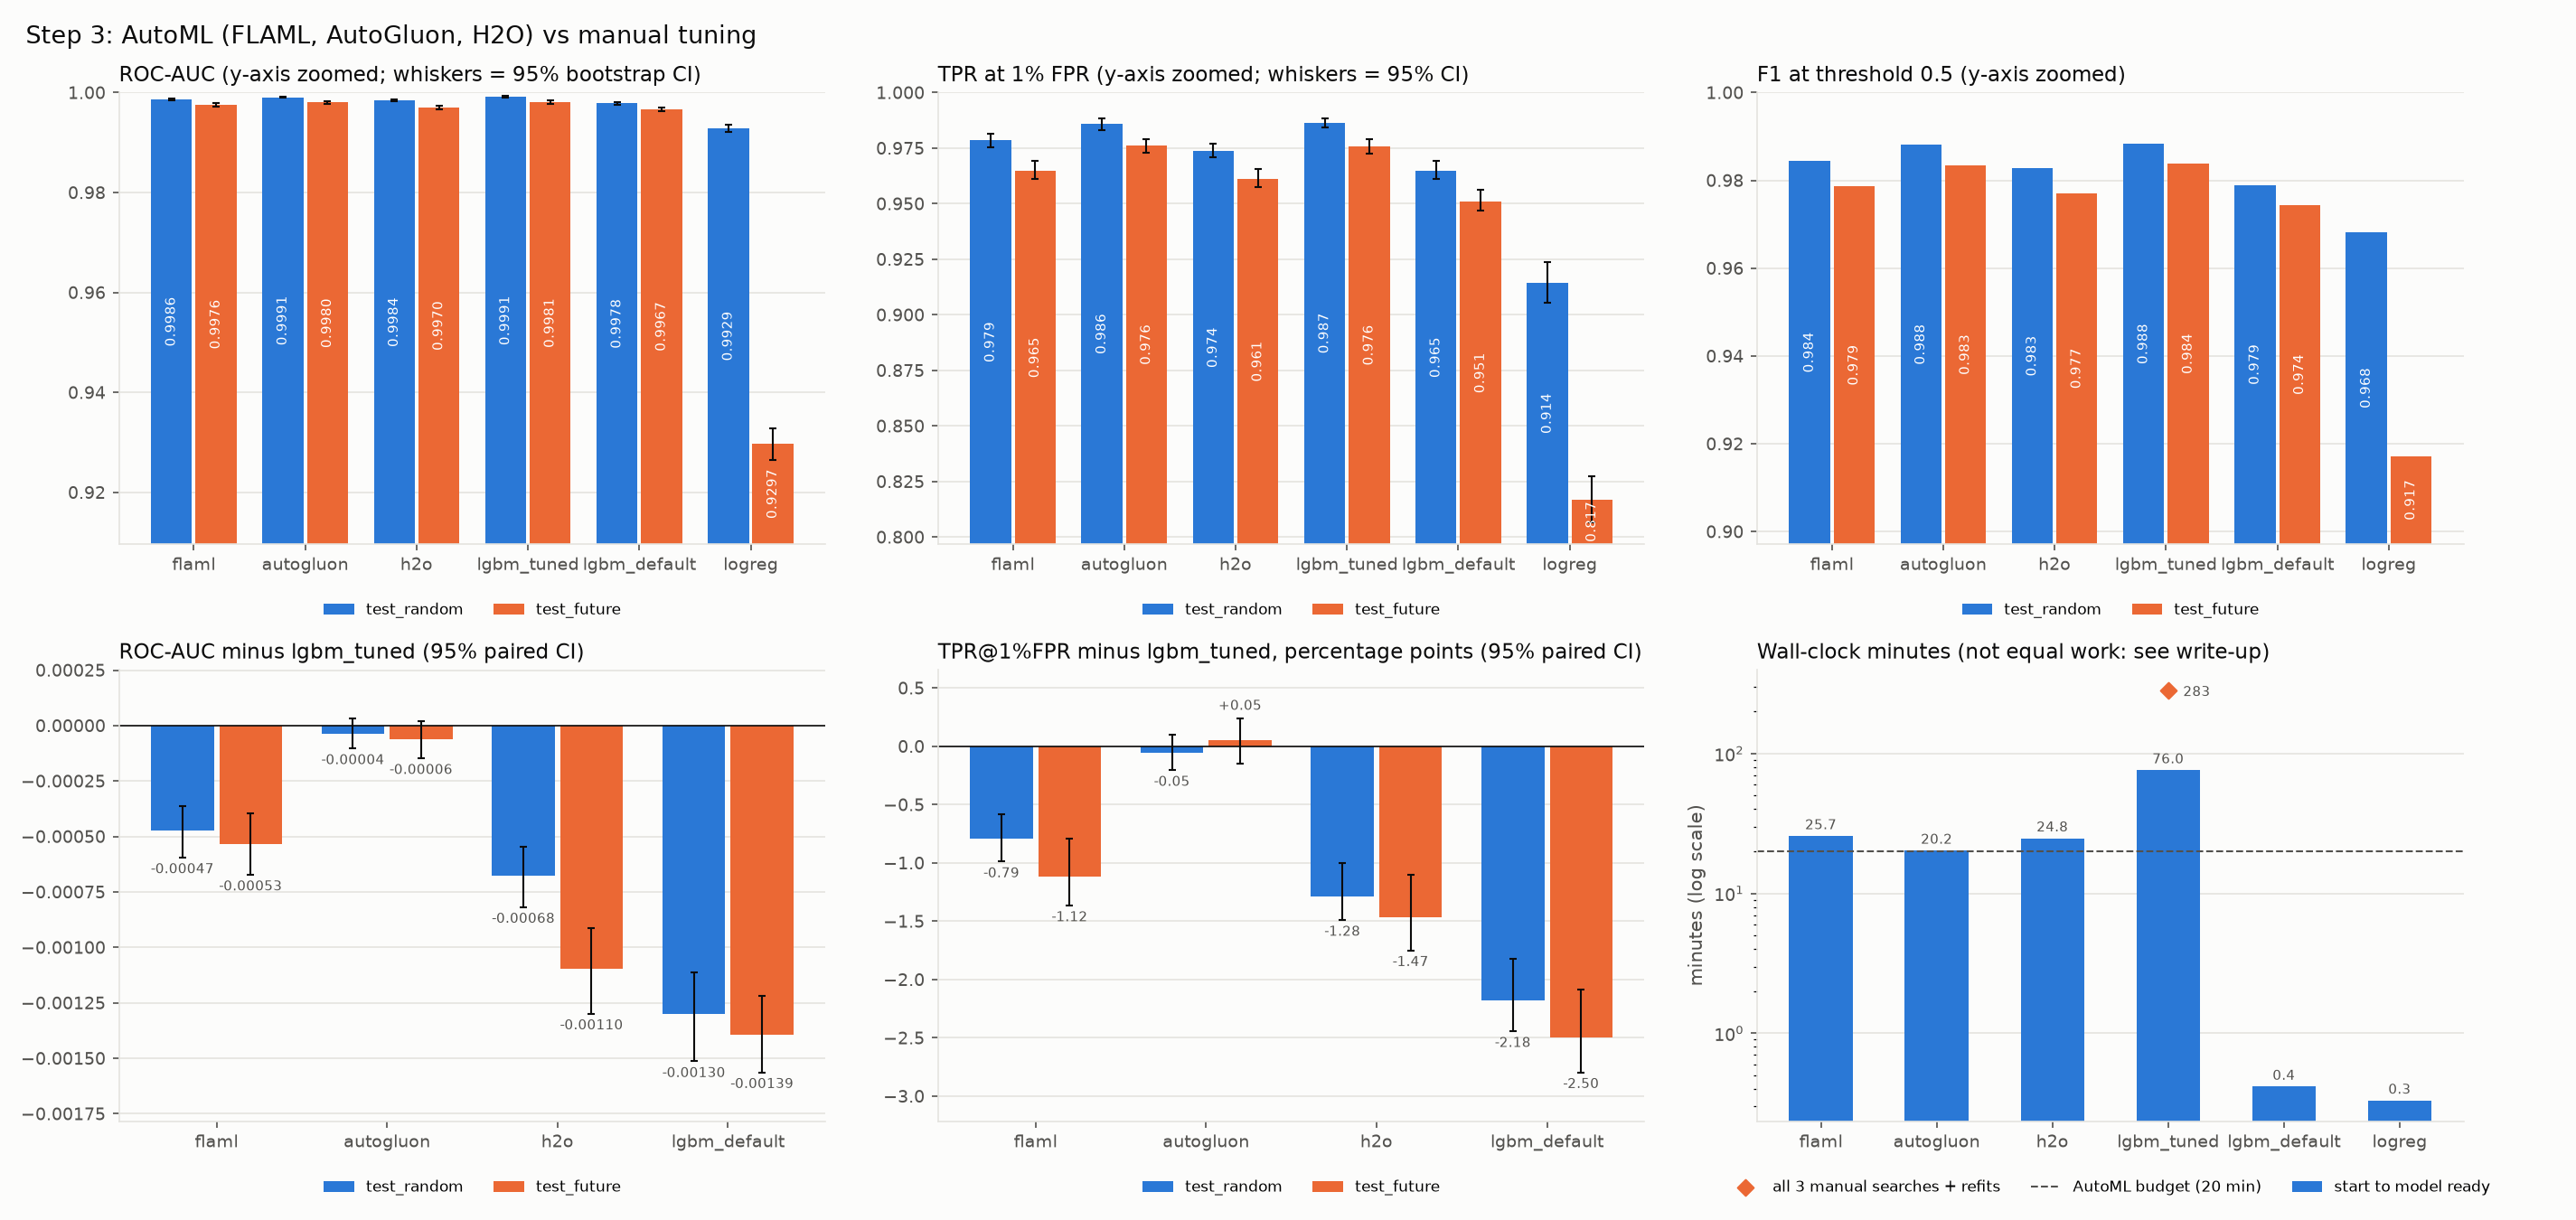

In [5]:
figure("automl_vs_manual")

## Which differences are real?

Paired bootstrap of each AutoML tool against the tuned and the default LightGBM, on the same
resampled test rows. Only rows whose 95% CI excludes zero (`significant_95`) are real differences.

In [6]:
pairwise = table("automl_pairwise")
pairwise[pairwise["test_set"] == "test_future"]

,test_set,metric,method_a,method_b,diff_a_minus_b,ci_low,ci_high,share_resamples_a_better,significant_95
20,test_future,roc_auc,flaml,lgbm_tuned,-0.000534,-0.000673,-0.000396,0.000,True
21,test_future,roc_auc,flaml,lgbm_default,0.000860,0.000698,0.001009,1.000,True
22,test_future,roc_auc,autogluon,lgbm_tuned,-0.000061,-0.000147,0.000018,0.065,False
23,test_future,roc_auc,autogluon,lgbm_default,0.001333,0.001167,0.001495,1.000,True
24,test_future,roc_auc,h2o,lgbm_tuned,-0.001098,-0.001299,-0.000914,0.000,True
25,test_future,roc_auc,h2o,lgbm_default,0.000295,0.000079,0.000492,0.997,True
26,test_future,roc_auc,lgbm_default,lgbm_tuned,-0.001394,-0.001563,-0.001219,0.000,True
27,test_future,roc_auc,flaml,autogluon,-0.000473,-0.000615,-0.000323,0.000,True
28,test_future,roc_auc,flaml,h2o,0.000565,0.000356,0.000780,1.000,True
29,test_future,roc_auc,autogluon,h2o,0.001038,0.000861,0.001213,1.000,True


## What each tool tried and what won

Each tool's own leaderboard, as saved after its run. The validation scores here come from each tool's
**own** validation rows inside `train`, not from a test set. That is why they can be higher than the
test scores above.

In [7]:
for tool in ["flaml", "autogluon", "h2o"]:
    board = pd.read_csv(config.LEADERBOARDS / f"{tool}_leaderboard{config.RUN_SUFFIX}.csv")
    print(f"{tool}: {len(board)} rows")
    display(board.head(5))

flaml: 8 rows


,rank,estimator,n_trials,best_val_loss,best_val_auc,best_record_id,best_found_at_s,best_sample_size,max_sample_size,total_trial_time_s,best_config
0,1,xgb_limitdepth,17,0.001487,0.998513,98,996.410372,144000,144000,241.639419,"{""FLAML_sample_size"": 144000, ""colsample_bylev..."
1,2,extra_tree,26,0.003154,0.996846,101,1055.603682,144000,144000,154.940902,"{""FLAML_sample_size"": 144000, ""criterion"": ""en..."
2,3,lgbm,25,0.004518,0.995482,43,245.525346,10000,10000,241.870313,"{""FLAML_sample_size"": 10000, ""colsample_bytree..."
3,4,catboost,2,0.005782,0.994218,57,669.501360,10000,10000,314.628198,"{""FLAML_sample_size"": 10000, ""early_stopping_r..."
4,5,xgboost,11,0.006671,0.993329,84,806.593816,10000,10000,57.991148,"{""FLAML_sample_size"": 10000, ""colsample_byleve..."


autogluon: 6 rows


,model,score_val,eval_metric,pred_time_val,fit_time,stack_level,can_infer,fit_order,num_features,num_models
0,LightGBMXT,0.999404,roc_auc,0.218445,394.403803,1,True,1,2515,1
1,WeightedEnsemble_L2,0.999404,roc_auc,0.220441,394.489804,2,True,6,1,1
2,LightGBM,0.999242,roc_auc,0.148902,297.621456,1,True,2,2515,1
3,RandomForestEntr,0.998089,roc_auc,0.151583,162.258521,1,True,4,2515,1
4,RandomForestGini,0.997913,roc_auc,0.151119,256.358210,1,True,3,2515,1


h2o: 9 rows


,model_id,auc,logloss,aucpr,mean_per_class_error,rmse,mse,training_time_ms,predict_time_per_row_ms,algo
0,StackedEnsemble_BestOfFamily_1_AutoML_1_202610...,0.998448,0.046908,0.998589,0.016515,0.113603,0.012906,26807,0.215792,StackedEnsemble
1,StackedEnsemble_BestOfFamily_2_AutoML_1_202610...,0.998448,0.046908,0.998589,0.016515,0.113603,0.012906,18211,0.215779,StackedEnsemble
2,StackedEnsemble_AllModels_1_AutoML_1_20261029_...,0.998448,0.046908,0.998589,0.016515,0.113603,0.012906,35241,0.214844,StackedEnsemble
3,GBM_1_AutoML_1_20261029_80743,0.998445,0.047767,0.998588,0.016515,0.113814,0.012954,454169,0.220661,GBM
4,DRF_1_AutoML_1_20261029_80743,0.994192,0.110190,0.994840,0.033498,0.169755,0.028817,39033,0.166735,DRF


## Preprocessing and validation, from the tools' own notes

After each run we saved what the tool did to the data (dropped columns, imputation, new features)
and how it validated. This matters for Step 4: a tool that validates on a random split of `train`
cannot notice temporal drift.

In [8]:
keys = ["best_estimator", "eval_method", "n_features_in", "n_features_used", "dropped_features",
        "new_features_created", "imputation", "feature_engineering"]
notes = {}
for tool in ["flaml", "autogluon", "h2o"]:
    path = config.LEADERBOARDS / f"{tool}_preprocessing{config.RUN_SUFFIX}.json"
    data = json.loads(path.read_text(encoding="utf-8"))
    # list-valued notes (e.g. dropped column names) are shown as counts to keep the table short
    notes[tool] = {k: (f"{len(v)} items" if isinstance(v, list) else v) for k, v in data.items() if k in keys}
pd.DataFrame(notes)

,flaml,autogluon,h2o
best_estimator,xgb_limitdepth,NaN,NaN
eval_method,holdout,NaN,NaN
n_features_in,2568,2568,2568
n_features_used,2533,2515,NaN
dropped_features,35 items,53 items,35 items
new_features_created,0 items,0 items,0 items
imputation,SimpleImputer(strategy='median') on numeric co...,NaN,NaN
feature_engineering,"none (FLAML only converts types, drops constan...",NaN,NaN


## Verdict

Is AutoML better, worse or just different? The generated verdict, read from the write-up:

In [9]:
section("automl_comparison", "### Verdict")

### Verdict

* **FLAML**: worse than `lgbm_tuned` on test_future (AUC -0.00053 [-0.00067, -0.00040], TPR@1%FPR -1.12 pp [-1.37 pp, -0.79 pp]); better than `lgbm_default` on test_future (AUC +0.00086 [+0.00070, +0.00101], TPR@1%FPR +1.38 pp [+1.03 pp, +1.72 pp]). It needed 25.7 wall minutes, against 76.0 for the selected manual search (283.5 for all three). Winner: one `xgb_limitdepth` (XGBoost) model found by FLAML's search of 105 trials, retrained on all rows.
* **AutoGluon**: statistically tied with `lgbm_tuned` on test_future (AUC -0.00006 [-0.00015, +0.00002], TPR@1%FPR +0.05 pp [-0.15 pp, +0.24 pp]); better than `lgbm_default` on test_future (AUC +0.00133 [+0.00117, +0.00149], TPR@1%FPR +2.55 pp [+2.12 pp, +2.84 pp]). It needed 20.2 wall minutes, against 76.0 for the selected manual search (283.5 for all three). Winner: a single `LightGBMXT` (all ensemble weight) with AutoGluon's preset hyperparameters (`hyperparameters='default'`), i.e. no search: AutoGluon matched the tuned model with one LightGBM at preset settings, trained on nearly all rows.
* **H2O AutoML**: worse than `lgbm_tuned` on test_future (AUC -0.00110 [-0.00130, -0.00091], TPR@1%FPR -1.47 pp [-1.75 pp, -1.10 pp]); better than `lgbm_default` on test_future (AUC +0.00030 [+0.00008, +0.00049], TPR@1%FPR +1.03 pp [+0.64 pp, +1.39 pp]). It needed 24.8 wall minutes, against 76.0 for the selected manual search (283.5 for all three). Winner: a stacked ensemble that is in effect one `GBM_1` (metalearner weight 0 on the other base model), trained on the 112,141-row training frame (70% of train) without a refit on all rows; training on fewer rows is a plausible part of why H2O ranks last among the tools.

Better: cost. Every tool reached its result in at most 34% of the selected manual search's wall time, with no search space to design. Worse: FLAML did not reach `lgbm_tuned` on test_future AUC (possibly because its budget was below its own "necessary" estimate of 5250 s); H2O AutoML did not reach `lgbm_tuned` on test_future AUC (plausibly in part because its models trained on 70% of train). AutoGluon is statistically tied with `lgbm_tuned`. Merely different: after checking the ensemble weights, every winner is in effect one tree model, so in principle none is harder to explain than `lgbm_tuned`. In practice the H2O winner must be explained through its base model `GBM_1` inside a running H2O cluster, since no MOJO could be exported (only an H2O binary model was saved). The random-split overstatement is about the same as `lgbm_tuned`'s for every tool except H2O AutoML, whose AUC gap is slightly but measurably larger (see above).


## Time

A fixed budget per tool against the hours the manual searches took. No tool stopped exactly on
time: AutoGluon finished within seconds of its budget, while FLAML and H2O ran minutes past it. The
table in the write-up shows by how much, and why.

In [10]:
section("automl_comparison", "## Time")

## Time: a 20-minute budget per tool versus hours of manual search

| tool | budget s | cluster start s | data conversion s | fit s | wall s | fit over budget s | wall over budget s |
|---|---|---|---|---|---|---|---|
| FLAML | 1200 | 0 | 0 | 1542 | 1542 | +342 | +342 |
| AutoGluon | 1200 | 0 | 0 | 1215 | 1215 | +15 | +15 |
| H2O AutoML | 1200 | 25 | 166 | 1296 | 1487 | +96 | +287 |

Wall = cluster start + data conversion + fit, i.e. start to "model ready"; saving artefacts and scoring the
test sets are logged separately (`artifacts_s`, `score_s` in the log). "Fit over budget" is how far the tool's
own fit call ran past its search budget (for FLAML, see its section: a trial started before the deadline and the
final retrain). "Wall over budget" also counts set-up that is not search: H2O AutoML 191 s of start-up and data conversion against +96 s of fit over budget.

More time did not buy more quality here: FLAML used 27% more wall time than AutoGluon (1542 s vs 1215 s) and still scored lower (paired test_future AUC difference -0.00047 [-0.00062, -0.00032], flaml minus autogluon); H2O AutoML used 22% more wall time than AutoGluon (1487 s vs 1215 s) and still scored lower (paired test_future AUC difference +0.00104 [+0.00086, +0.00121], autogluon minus h2o).

Manual tuning: the selected tuner `optuna` took 1.24 h of search plus
107 s for the final refit; all three manual searches with their refits took
4.72 h. The three AutoML tools together took 1.18 h.

This is **not an apples-to-apples comparison**. The manual searches were not time-capped (equal budget meant
equal configurations: 36 trials x 3 folds), they searched one model family on a
60,000-row subset with 3-fold CV, and three of them were run to compare search methods, not
to get one model fast. The AutoML tools had a hard search budget, each received all
160,000 rows but used them its own way (see Setup), and spread the
budget over several model families. A fair reading is:
"this is the quality each approach reached at these very different costs" (see the paired differences above),
not "AutoML is N times faster at the same job".


## Completeness check

The experiment log should hold one final record per AutoML tool in the current mode.

In [11]:
from src.logging_utils import read_experiments

log = read_experiments()
log = log[(log["step"] == "automl") & (log["quick"] == config.QUICK)]
log[["method", "kind", "test_random.roc_auc", "test_future.roc_auc", "train_rows"]]

,method,kind,test_random.roc_auc,test_future.roc_auc,train_rows
123,automl_flaml,final_eval,0.998642,0.997571,160000.0
124,automl_autogluon,final_eval,0.999076,0.998044,160000.0
125,automl_h2o,final_eval,0.998437,0.997007,160000.0
